# What the extra GLM-HMM states are, as K grows (K = 2, 3, 4)

`fig_engagement` uses K = 2 (engaged / disengaged); `k_state_model_comparison` shows K = 3 helps held-out fit in most sessions and K = 4 much less, and that the switching–LD1 result survives both. This notebook asks what the states *are* at K = 3 and 4, and how they unfold within sessions:

1. **Weights** — each state's GLM (stimulus, previous choice, win-stay/lose-switch, bias).
2. **Behaviour** — psychometric and chronometric curves per state (RT is not in the model: the independent check), easy-trial accuracy.
3. **Nesting** — which K = 2 state each K = 3 / K = 4 state takes its trials from.
4. **Dynamics** — occupancy, bout (dwell) lengths, transition matrices, time course within the session, example sessions.
5. **Along LD1** — occupancy and bout length of each state vs mouse-mean LD1.

**Inputs** (no refitting): `GLM-HMM/k2_k3_pilot/all_k_weights.csv` and `all_k_posteriors.parquet` (`fit_and_save_all_k.py`: full-data fits per mouse, K = 2–4, 54 mice, 242 sessions); trial outcomes from `merged_behavioral_and_states.pqt` (same sessions, same trial order — checked below); RTs from the session trial meta, as `fig_engagement`.

**State labels.** EM numbering is arbitrary per mouse, so within each mouse and K the states are ranked by stimulus weight: **S1** = steepest psychometric (the engaged state), S2 next, ... Ranks are comparable across mice only to the degree the states are; section 1 shows how far that holds. Weights are sign-flipped to be for the **right** choice (ssm stores the logit of y = 0 = left; as `fig_engagement` panel b). For the bias-split question the non-engaged states are also described by the side their bias points to.

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'trial_modes.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
PI = REPO / 'paper-individuality'
sys.path.insert(0, str(PI))
import paper_style as ps
ps.use('paper')
pd.set_option('display.width', 160)

PILOT = PI / 'GLM-HMM' / 'k2_k3_pilot'
TRIAL_META = next(f for f in [PI / 'data' / 'session_trial_meta_10-07-2026', PI / 'data' / 'session_trial_meta_19-08-2026'] if f.exists())
LDA_FILE = PI / 'clustering' / 'data_files' / 'mouse_LDA_5_bins_raw_shrink0.5_wmouse_360_02-10-2026'
KS = [2, 3, 4]
REGRESSORS = ['stim', 'prev_choice', 'wsls', 'bias']
RT_WINDOW = (0, 2)          # s, as fig_engagement
N_TRUNC = 400               # time course / switching: first trials of each session (shortest: 401)
TIME_BIN = 25               # trials per bin in the within-session time course
RANK_COLOR = {1: '#1b1b1b', 2: '#3182bd', 3: '#e6550d', 4: '#31a354'}
AREA_COLOR = {**RANK_COLOR, 1: '#d9d9d9'}   # filled areas: the engaged state pale, so the others stand out

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Data

In [2]:
W = pd.read_csv(PILOT / 'all_k_weights.csv')
W[REGRESSORS] = -W[REGRESSORS]                                     # -> weights for the RIGHT choice
W['rank'] = W.groupby(['mouse_name', 'K'])['stim'].rank(ascending=False, method='first').astype(int)
RANK = W.set_index(['mouse_name', 'K', 'state'])['rank']

post = pd.read_parquet(PILOT / 'all_k_posteriors.parquet')
P = post.pivot_table(index=['mouse_name', 'eid', 'trial_idx'], columns=['K', 'state'], values='posterior')
lab = {}
for k in KS:
    pk = P[k].dropna(axis=1, how='all')
    hard = pk.to_numpy().argmax(axis=1)
    mice = P.index.get_level_values('mouse_name')
    lab[k] = pd.Series([RANK[(m, k, s)] for m, s in zip(mice, hard)], index=P.index)
    lab[f'pmax{k}'] = pd.Series(pk.to_numpy().max(axis=1), index=P.index)
T = pd.DataFrame({f'S_K{k}': lab[k] for k in KS} | {f'pmax_K{k}': lab[f'pmax{k}'] for k in KS}).reset_index()

beh = pd.read_parquet(PI / 'GLM-HMM' / 'merged_behavioral_and_states.pqt')
beh = beh[beh['eid'].isin(T['eid'])].copy()
beh['trial_idx'] = beh.groupby('eid').cumcount()
beh['choice_right'] = ((beh['contrastLeft'].isna() & (beh['rewarded'] == 1))
                       | (beh['contrastRight'].isna() & (beh['rewarded'] == -1))).astype(int)
beh['correct'] = (beh['rewarded'] == 1).astype(int)
assert beh.groupby('eid').size().equals(T.groupby('eid').size()), 'trial counts differ'
T = T.merge(beh[['eid', 'trial_idx', 'signed_contrast', 'choice_right', 'correct']], on=['eid', 'trial_idx'])
meta = pd.read_parquet(TRIAL_META, columns=['session', 'trial_id', 'reaction'])
T = T.merge(meta.rename(columns={'session': 'eid', 'trial_id': 'trial_idx'}), on=['eid', 'trial_idx'], how='left')
T['rt'] = T['reaction'].where(T['reaction'].between(*RT_WINDOW))

lda = pd.read_pickle(LDA_FILE).rename(columns={0: 'LD1'})
LD1_MOUSE = lda.groupby('mouse_name')['LD1'].mean()
print(f"{T['eid'].nunique()} sessions, {T['mouse_name'].nunique()} mice, {len(T):,} trials; RT for {T['rt'].notna().mean():.0%}")
print('hard-label agreement of the K=2 refit with fig_engagement is checked in fig_engagement (r = 0.89 on P(engaged))')

242 sessions, 54 mice, 153,481 trials; RT for 76%
hard-label agreement of the K=2 refit with fig_engagement is checked in fig_engagement (r = 0.89 on P(engaged))


## 1. Weights — what each state is

One dot per mouse per state, ranked by stimulus weight within mouse (S1 = engaged). Medians as bars. The bias is shown as the mouse's own signed bias and as |bias|.

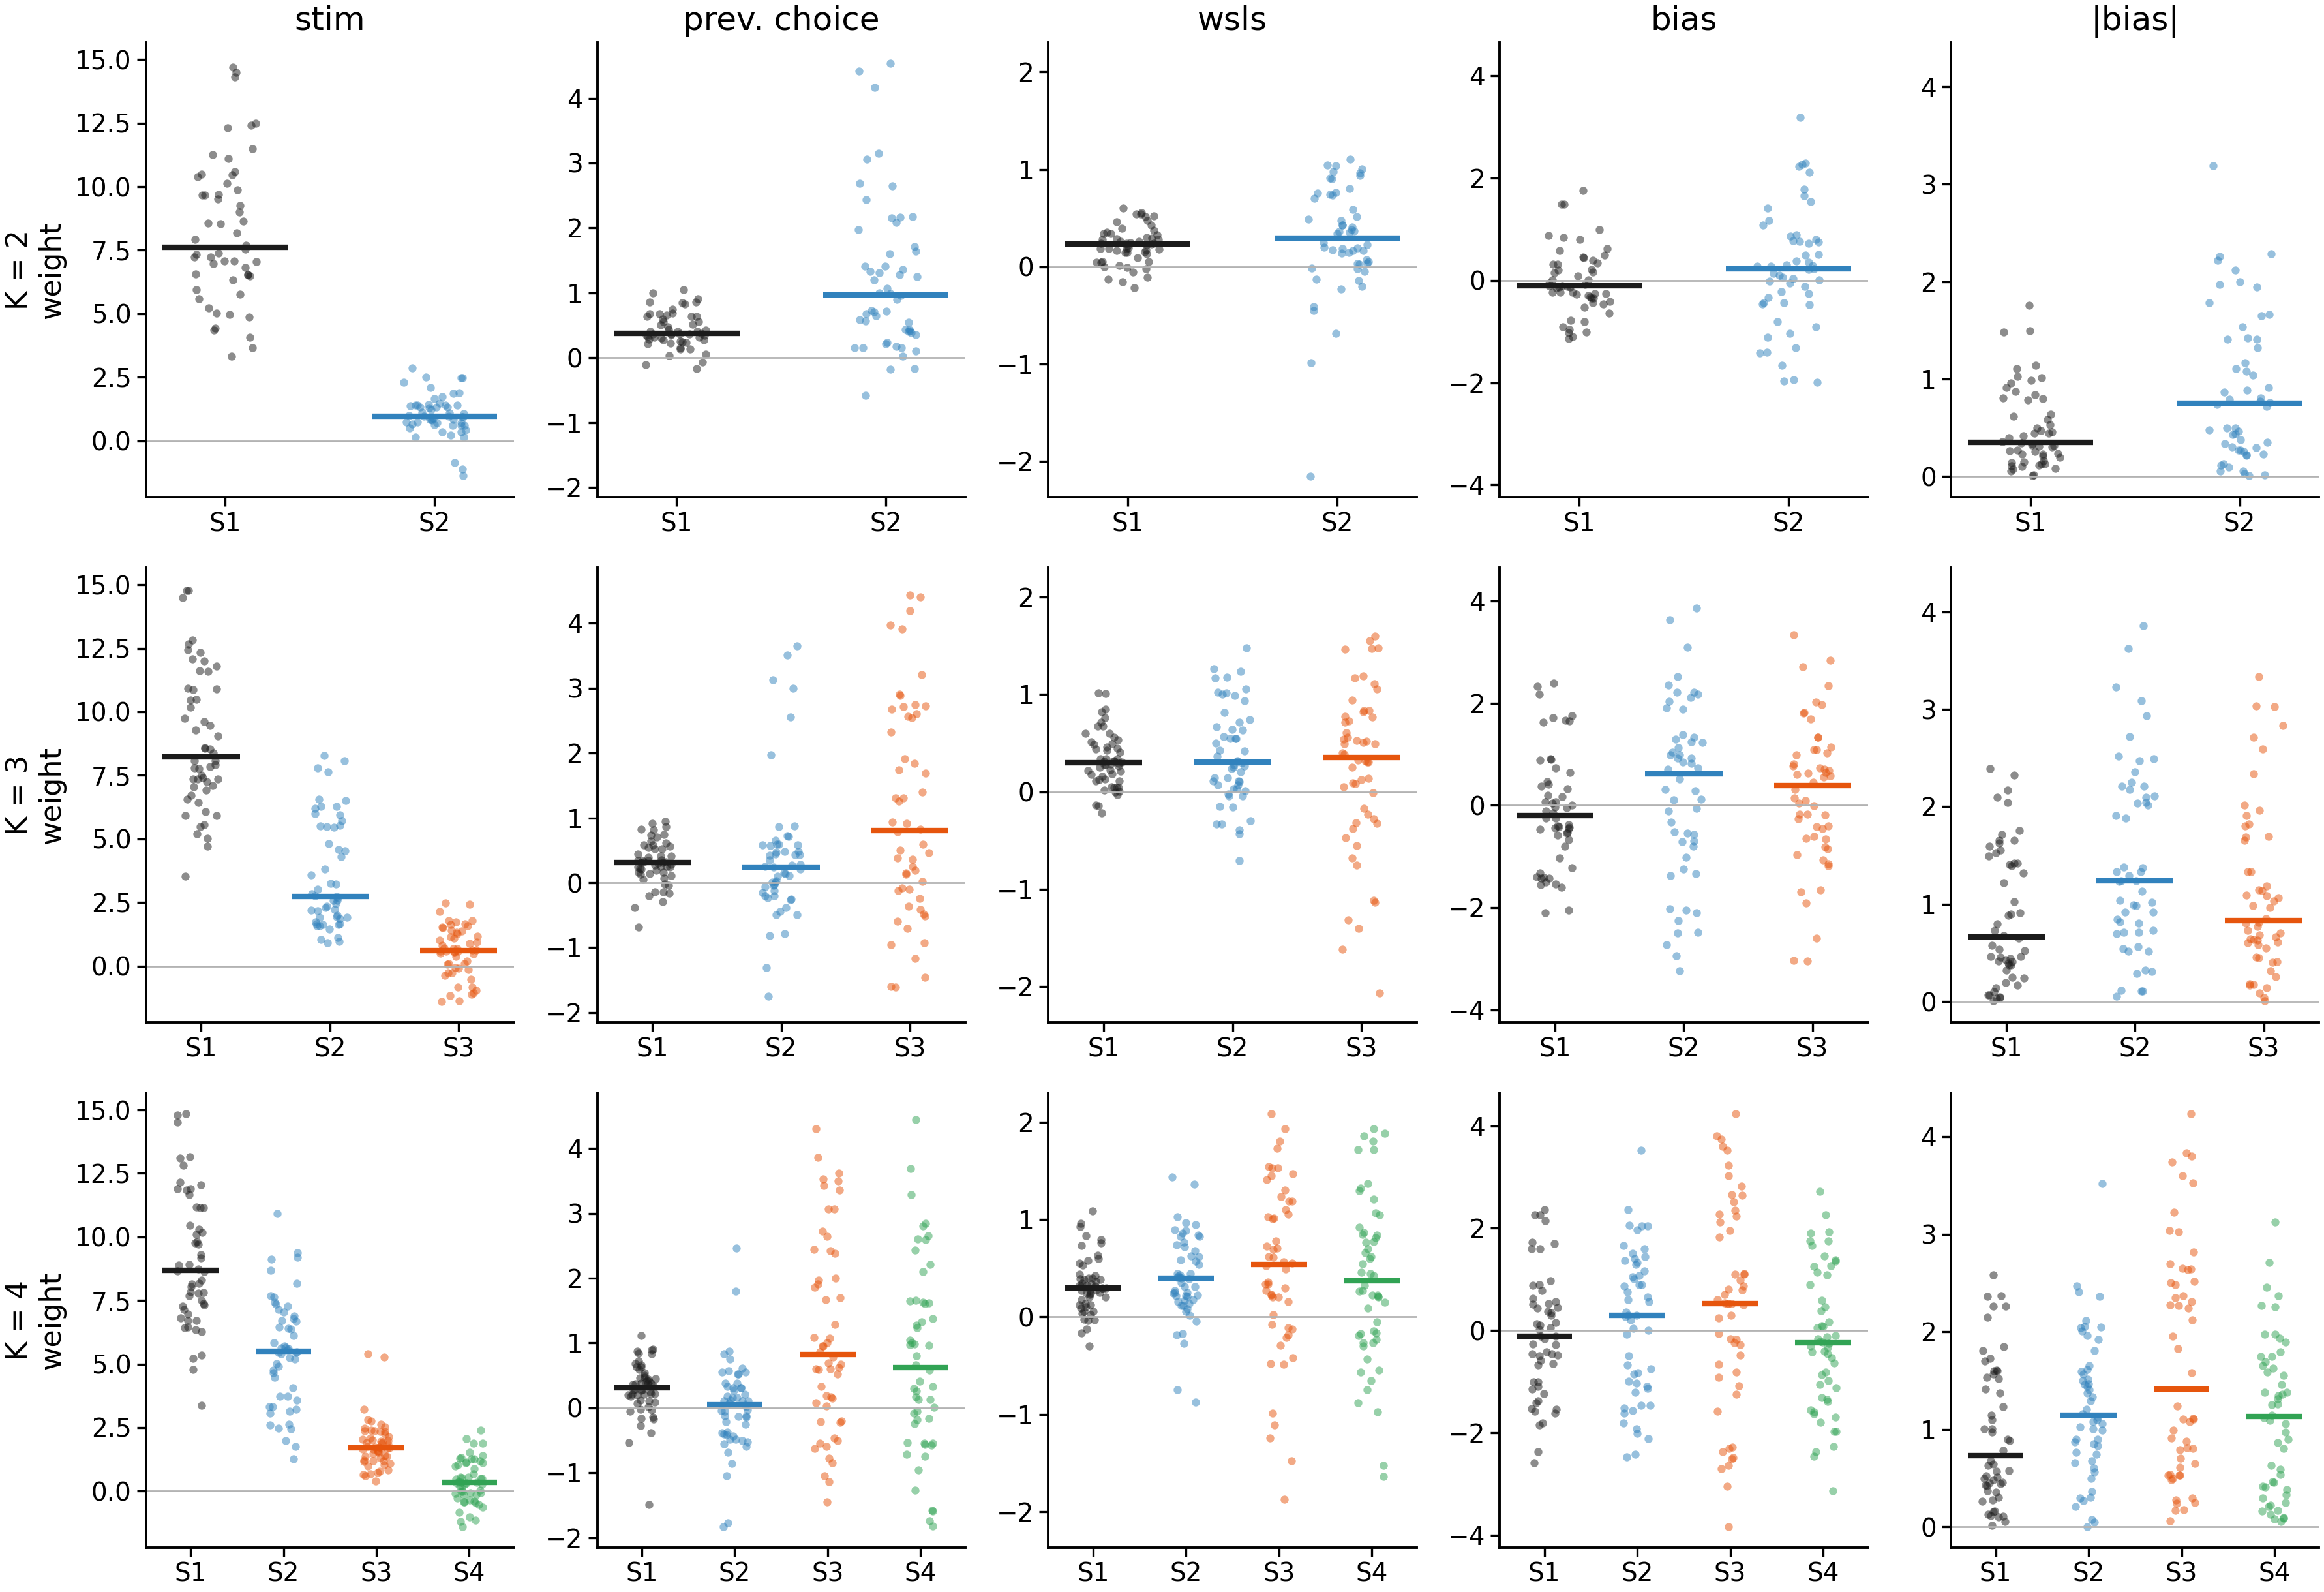

median weights (IQR) by K and rank:
        stim  prev_choice  wsls  bias  abs_bias
K rank                                         
2 1     7.61         0.37  0.23 -0.11      0.35
  2     0.98         0.97  0.29  0.22      0.75
3 1     8.24         0.32  0.30 -0.19      0.66
  2     2.74         0.25  0.31  0.61      1.24
  3     0.61         0.81  0.35  0.38      0.83
4 1     8.69         0.31  0.30 -0.11      0.73
  2     5.51         0.05  0.40  0.30      1.14
  3     1.71         0.82  0.54  0.53      1.41
  4     0.33         0.63  0.37 -0.24      1.13


In [3]:
fig, axes = plt.subplots(len(KS), len(REGRESSORS) + 1, figsize=(9, 2.1 * len(KS)), sharey='col')
rng = np.random.default_rng(0)
for r, k in enumerate(KS):
    wk = W[W['K'] == k]
    for c, reg in enumerate(REGRESSORS + ['abs_bias']):
        ax = axes[r, c]
        for s in range(1, k + 1):
            v = wk.loc[wk['rank'] == s, 'bias'].abs() if reg == 'abs_bias' else wk.loc[wk['rank'] == s, reg]
            ax.scatter(s + rng.uniform(-0.15, 0.15, len(v)), v, s=5, color=RANK_COLOR[s], alpha=0.5, lw=0)
            ax.hlines(v.median(), s - 0.3, s + 0.3, color=RANK_COLOR[s], lw=1.5)
        ax.axhline(0, color='0.7', lw=0.5)
        ax.set_xticks(range(1, k + 1)); ax.set_xticklabels([f'S{s}' for s in range(1, k + 1)])
        if r == 0: ax.set_title({'abs_bias': '|bias|', 'prev_choice': 'prev. choice'}.get(reg, reg))
        if c == 0: ax.set_ylabel(f'K = {k}\nweight')
fig.tight_layout(); plt.show()

print('median weights (IQR) by K and rank:')
summ = W.assign(abs_bias=W['bias'].abs()).groupby(['K', 'rank'])[REGRESSORS + ['abs_bias']].median().round(2)
print(summ.to_string())

In [4]:
# do the non-engaged states split by bias SIDE (the classic engaged / biased-left / biased-right)?
def split(g):
    b = g.loc[g['rank'] > 1, 'bias'].to_numpy()
    return pd.Series({'n_left': (b < 0).sum(), 'n_right': (b > 0).sum(), 'opposite': (b.min() < 0 < b.max())})
for k in [3, 4]:
    s = W[W['K'] == k].groupby('mouse_name').apply(split, include_groups=False)
    print(f'K = {k}: non-engaged states with bias on opposite sides in {s["opposite"].mean():.0%} of mice')

K = 3: non-engaged states with bias on opposite sides in 50% of mice
K = 4: non-engaged states with bias on opposite sides in 72% of mice


## 2. Behaviour per state

Trials labelled by their most probable state. Psychometric: P(right) vs signed contrast, averaged over mice (each mouse's curve first). Because each mouse's biased states lean their own way, which would cancel across mice, the second row **aligns** each state to its own bias: contrast and choice are mirrored for states whose bias weight is negative, so 'right' means 'toward the state's preferred side'. Chronometric: median RT vs |contrast|.

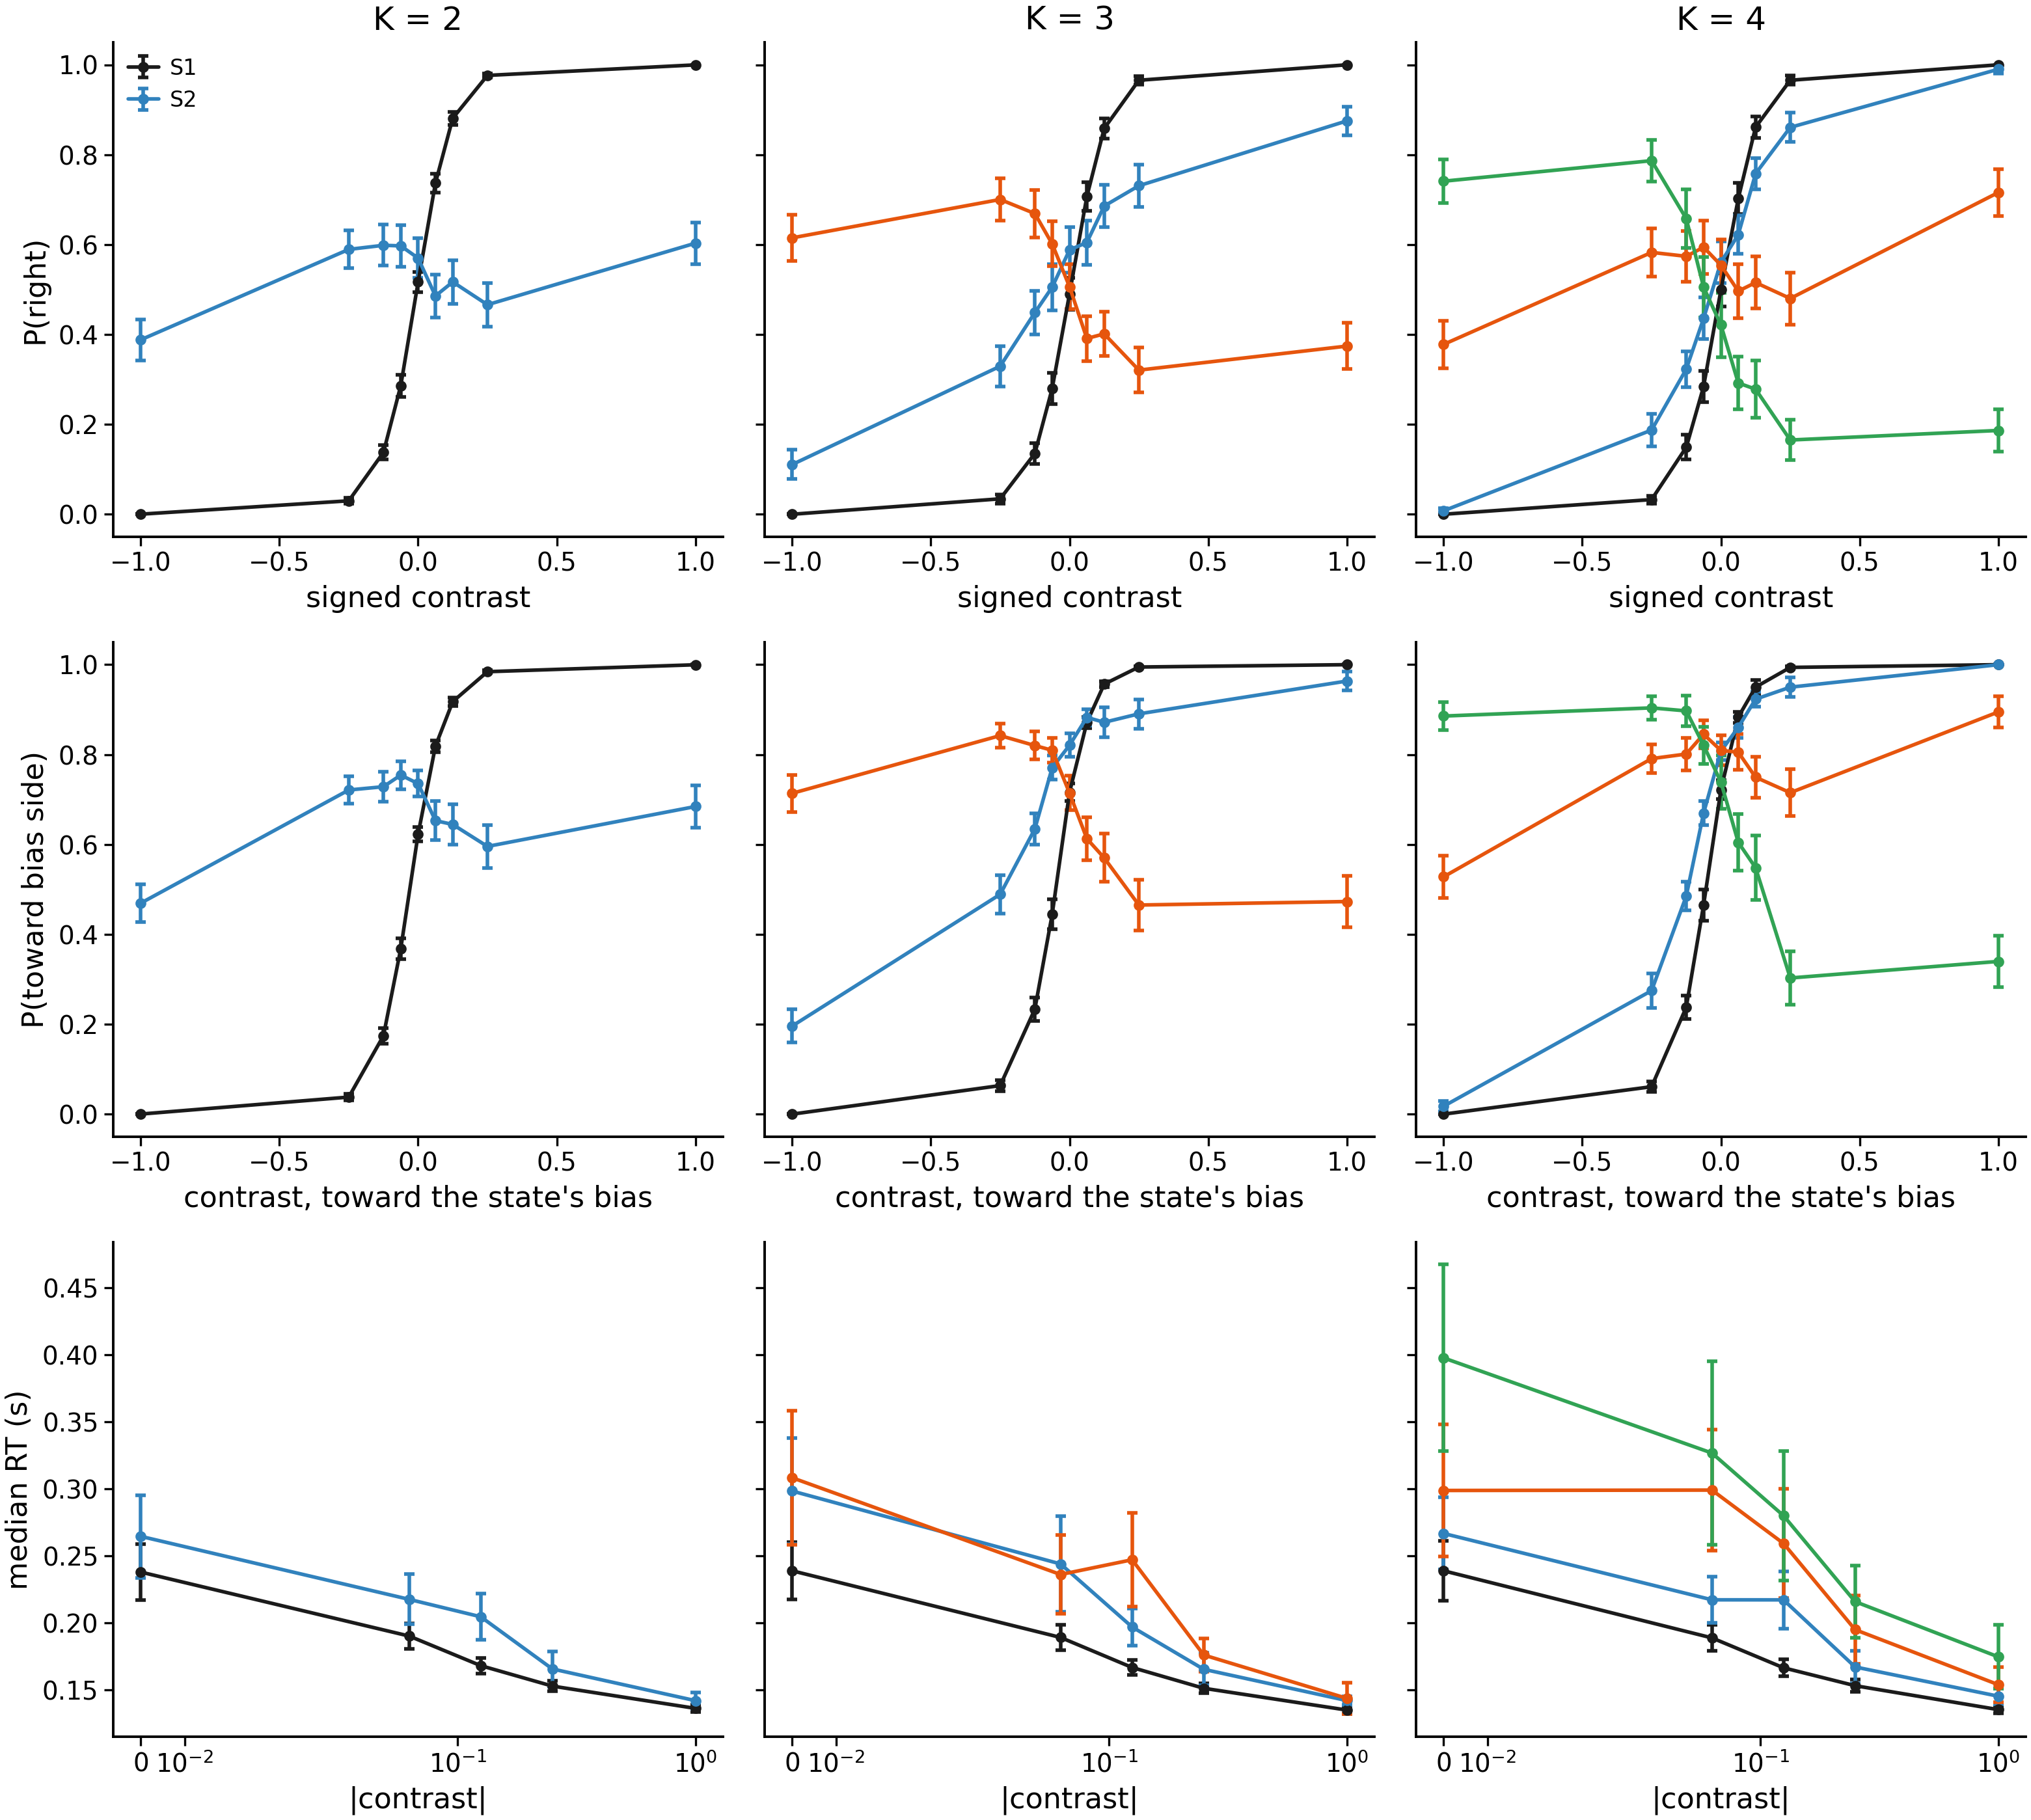

per state, median over mice: occupancy, easy-trial accuracy (|c| >= 25%), median RT
          occ  acc_easy     rt
K rank                        
2 1     0.884     0.993  0.153
  2     0.116     0.615  0.154
3 1     0.749     0.994  0.155
  2     0.198     0.874  0.156
  3     0.032     0.256  0.152
4 1     0.652     0.994  0.153
  2     0.252     0.956  0.162
  3     0.049     0.594  0.144
  4     0.010     0.066  0.153


In [5]:
def per_mouse_curve(d, ycol, xcol):
    return d.groupby(['mouse_name', xcol])[ycol].mean().unstack(xcol)

BIAS_SIGN = W.set_index(['mouse_name', 'K', 'rank'])['bias'].apply(np.sign)
fig, axes = plt.subplots(3, len(KS), figsize=(8, 7.2), sharey='row')
for c, k in enumerate(KS):
    d = T.dropna(subset=['signed_contrast']).copy()
    d['rank'] = d[f'S_K{k}']
    sgn = BIAS_SIGN.reindex(pd.MultiIndex.from_arrays([d['mouse_name'], np.full(len(d), k), d['rank']])).to_numpy()
    d['c_al'] = d['signed_contrast'] * sgn
    d['right_al'] = np.where(sgn > 0, d['choice_right'], 1 - d['choice_right'])
    d['abs_c'] = d['signed_contrast'].abs()
    for s in range(1, k + 1):
        ds = d[d['rank'] == s]
        if len(ds) < 100:
            continue
        for row, (xc, yc) in enumerate([('signed_contrast', 'choice_right'), ('c_al', 'right_al')]):
            cur = per_mouse_curve(ds, yc, xc)
            cur = cur.loc[:, ds.groupby(xc)['mouse_name'].nunique().reindex(cur.columns) >= 5]
            m, se = cur.mean(), cur.sem()
            axes[row, c].errorbar(m.index, m, se, color=RANK_COLOR[s], lw=1, marker='o', ms=2, label=f'S{s}')
        rt = ds.groupby(['mouse_name', 'abs_c'])['rt'].median().unstack('abs_c')
        axes[2, c].errorbar(rt.columns, rt.mean(), rt.sem(), color=RANK_COLOR[s], lw=1, marker='o', ms=2)
    axes[0, c].set_title(f'K = {k}')
    axes[0, c].set_xlabel('signed contrast'); axes[1, c].set_xlabel("contrast, toward the state's bias")
    axes[2, c].set_xlabel('|contrast|'); axes[2, c].set_xscale('symlog', linthresh=0.06)
axes[0, 0].set_ylabel('P(right)'); axes[1, 0].set_ylabel('P(toward bias side)'); axes[2, 0].set_ylabel('median RT (s)')
axes[0, 0].legend(frameon=False, fontsize=6)
fig.tight_layout(); plt.show()

rows = []
for k in KS:
    g = T.assign(rank=T[f'S_K{k}'], easy=T['signed_contrast'].abs() >= 0.25)
    per_m = g.groupby(['mouse_name', 'rank']).agg(occ=('rank', 'size'), acc_easy=('correct', lambda x: x[g.loc[x.index, 'easy']].mean()),
                                                 rt=('rt', 'median'))
    per_m['occ'] = per_m['occ'] / per_m.groupby('mouse_name')['occ'].transform('sum')
    rows.append(per_m.groupby('rank').median().assign(K=k))
BEH = pd.concat(rows).reset_index().set_index(['K', 'rank'])
print('per state, median over mice: occupancy, easy-trial accuracy (|c| >= 25%), median RT')
print(BEH.round(3).to_string())

## 3. Nesting — where the new states come from

For every trial, its K = 2 state against its K = 3 and K = 4 states (all mice pooled). Rows: the K = 2 state; the stacked bar shows how its trials are relabelled at the larger K.

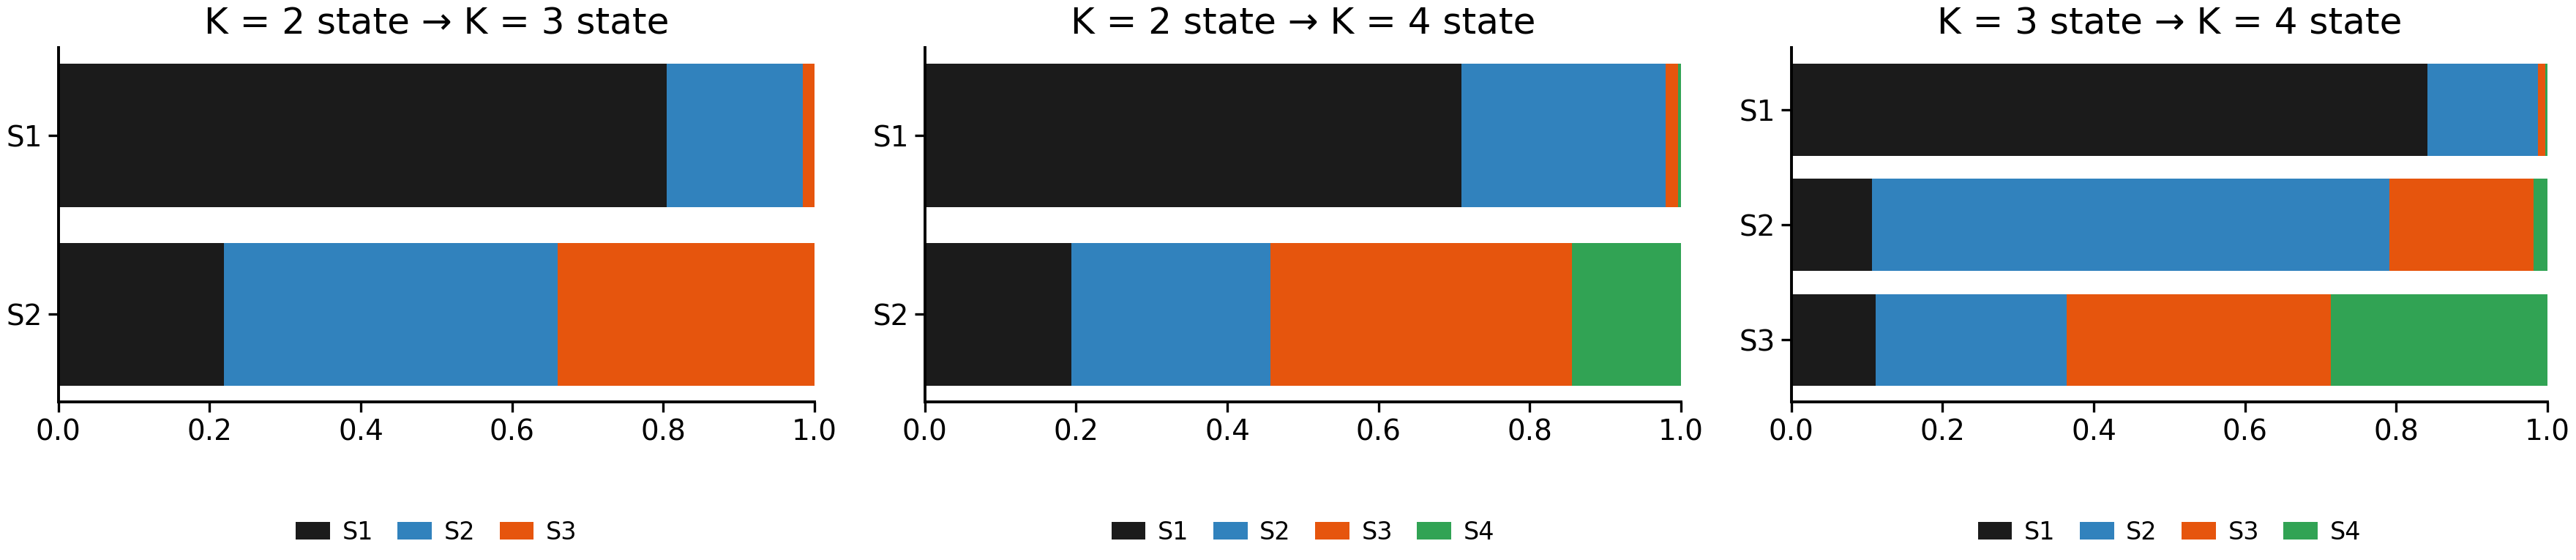

K=2 rows -> K=3 columns (fraction of row trials):
S_K3      1      2      3
S_K2                     
1     0.804  0.181  0.015
2     0.219  0.441  0.340 

K=2 rows -> K=4 columns (fraction of row trials):


S_K4      1      2      3      4
S_K2                            
1     0.709  0.271  0.016  0.004
2     0.193  0.263  0.399  0.144 

K=3 rows -> K=4 columns (fraction of row trials):
S_K4      1      2     3      4
S_K3                           
1     0.841  0.147  0.01  0.003
2     0.107  0.684  0.19  0.018
3     0.111  0.253  0.35  0.286 



In [6]:
fig, axes = plt.subplots(1, 3, figsize=(9, 2.4))
for ax, (ka, kb) in zip(axes, [(2, 3), (2, 4), (3, 4)]):
    ct = pd.crosstab(T[f'S_K{ka}'], T[f'S_K{kb}'], normalize='index')
    left = np.zeros(len(ct))
    for s in ct.columns:
        ax.barh([f'S{r}' for r in ct.index], ct[s], left=left, color=RANK_COLOR[s], label=f'S{s}')
        left += ct[s].to_numpy()
    ax.set_title(f'K = {ka} state → K = {kb} state'); ax.set_xlim(0, 1); ax.invert_yaxis()
    ax.legend(frameon=False, fontsize=6, ncol=kb, loc='lower center', bbox_to_anchor=(0.5, -0.45))
fig.tight_layout(); plt.show()
for ka, kb in [(2, 3), (2, 4), (3, 4)]:
    print(f'K={ka} rows -> K={kb} columns (fraction of row trials):')
    print(pd.crosstab(T[f'S_K{ka}'], T[f'S_K{kb}'], normalize='index').round(3).to_string(), '\n')

## 4. Dynamics

**Bouts**: runs of one hard label within a session. Per state: occupancy, number of bouts, mean bout length (dwell), per session, then median over sessions. **Transition matrix**: pooled hard-label transitions (row = trial t, column = t + 1), rank-ordered. **Time course**: occupancy of each state in bins of `TIME_BIN` trials over the first `N_TRUNC` trials.

per state, median over sessions that visit it: number of bouts, mean and median bout length (trials)
         n_bouts  mean  median
K state                       
2 1         10.0  53.7    34.8
  2          9.0   6.4     4.5
3 1         10.0  37.3    26.2
  2          6.0  18.3    15.0
  3          6.0   2.4     2.0
4 1          9.0  36.0    25.5
  2          7.0  20.2    15.0
  3          4.0   4.8     4.0
  4          4.0   1.2     1.0


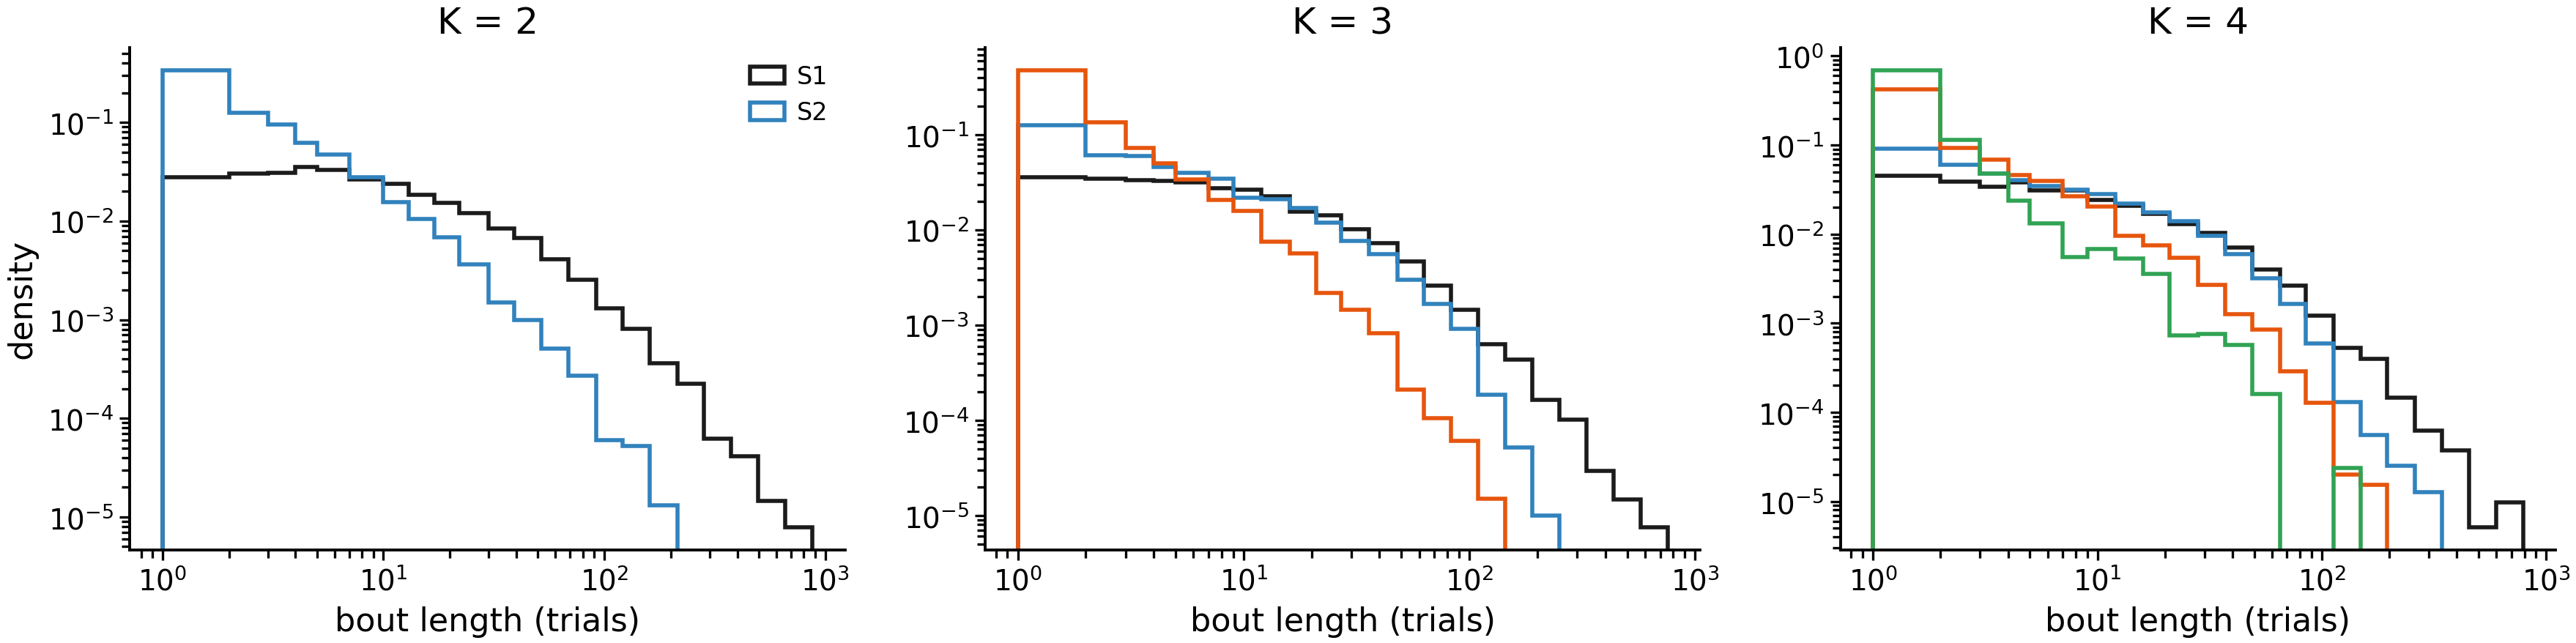

In [7]:
def bouts(labels):
    x = np.asarray(labels)
    edges = np.flatnonzero(np.diff(x)) + 1
    starts = np.r_[0, edges]; ends = np.r_[edges, len(x)]
    return pd.DataFrame({'state': x[starts], 'length': ends - starts})

B = []
for k in KS:
    for (m, e), g in T.groupby(['mouse_name', 'eid'], sort=False):
        b = bouts(g[f'S_K{k}'].to_numpy()).assign(K=k, mouse_name=m, eid=e)
        B.append(b)
B = pd.concat(B, ignore_index=True)
dwell = B.groupby(['K', 'eid', 'state'])['length'].agg(['size', 'mean', 'median']).rename(columns={'size': 'n_bouts'})
print('per state, median over sessions that visit it: number of bouts, mean and median bout length (trials)')
print(dwell.groupby(['K', 'state']).median().round(1).to_string())

fig, axes = plt.subplots(1, len(KS), figsize=(9, 2.4))
for ax, k in zip(axes, KS):
    bk = B[B['K'] == k]
    bins = np.unique(np.round(np.logspace(0, np.log10(bk['length'].max() + 1), 25)))
    for s in range(1, k + 1):
        ax.hist(bk.loc[bk['state'] == s, 'length'], bins=bins, histtype='step', color=RANK_COLOR[s], label=f'S{s}', density=True)
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('bout length (trials)'); ax.set_title(f'K = {k}')
axes[0].set_ylabel('density'); axes[0].legend(frameon=False, fontsize=6)
fig.tight_layout(); plt.show()

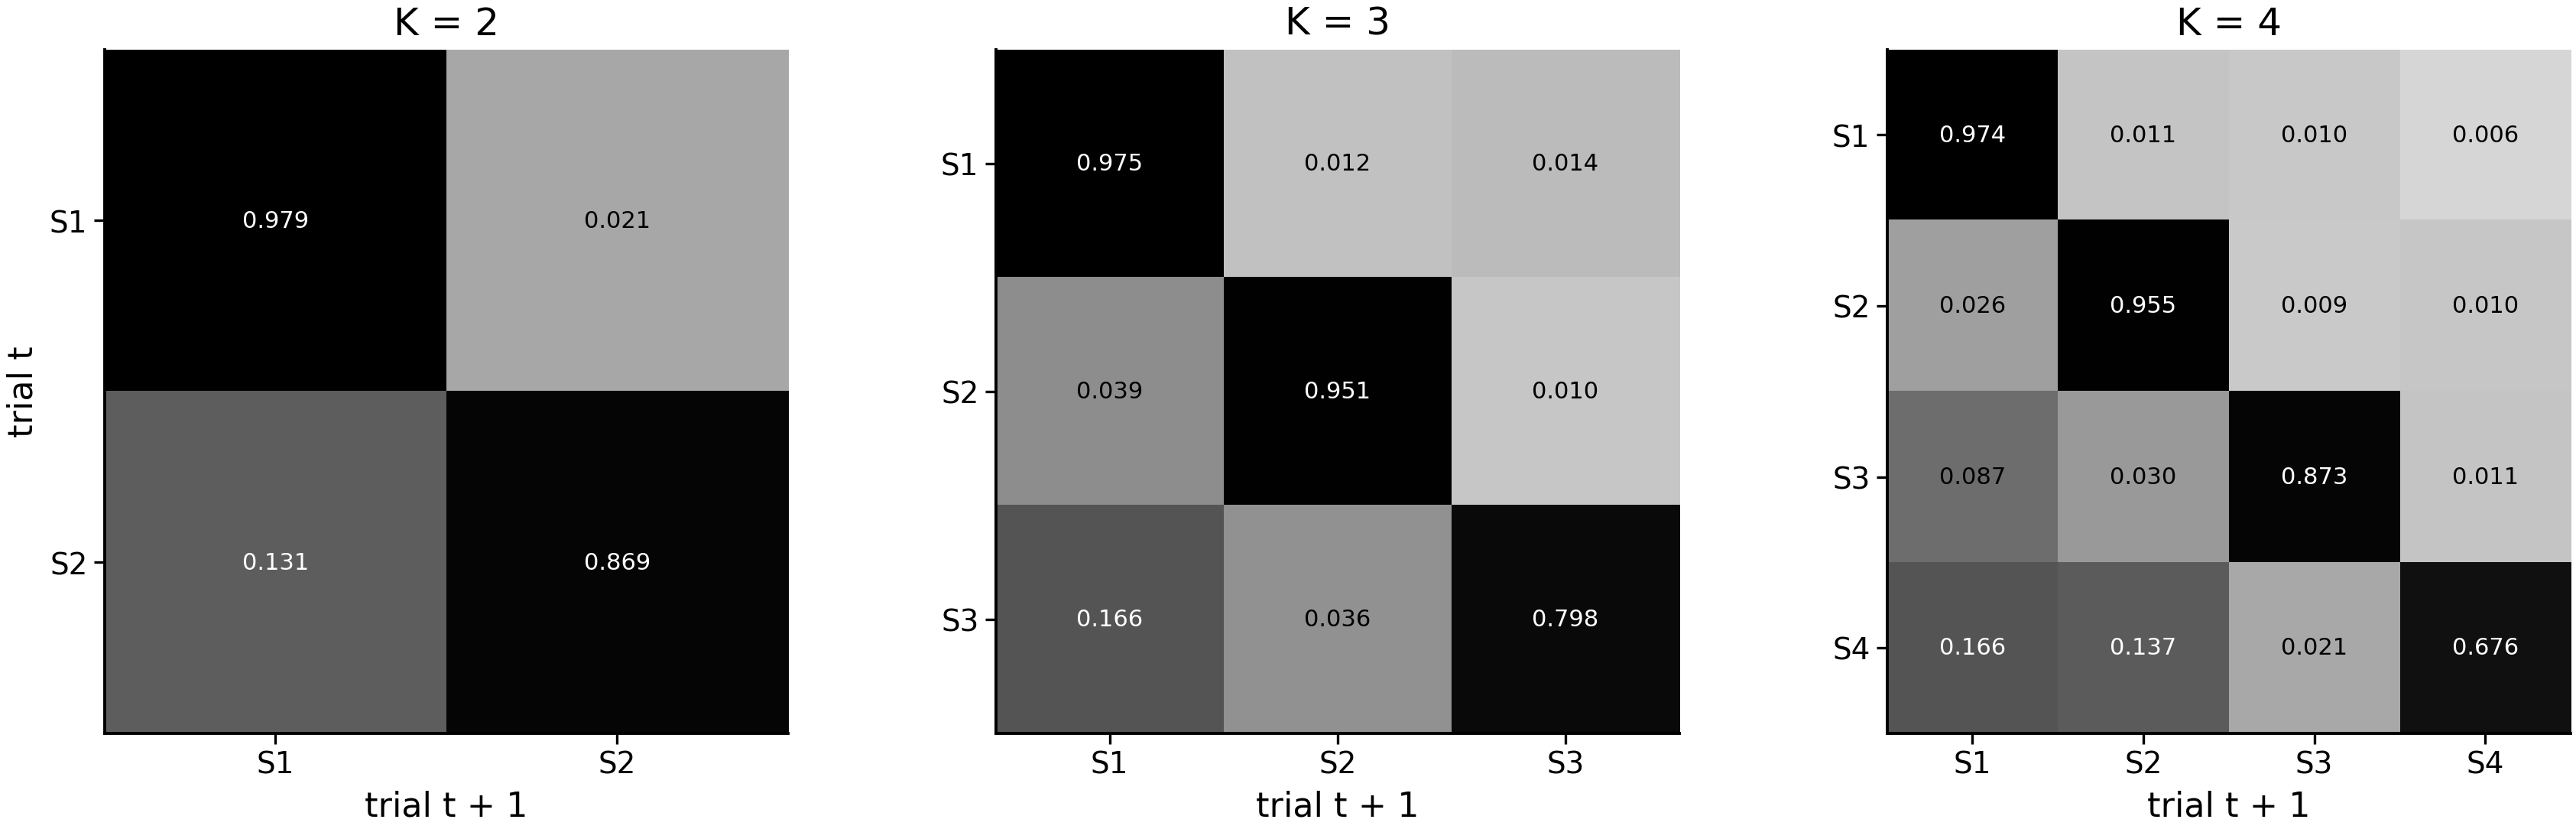

In [8]:
fig, axes = plt.subplots(1, len(KS), figsize=(9, 2.8))
for ax, k in zip(axes, KS):
    a = T[f'S_K{k}'].to_numpy(); same = T['eid'].to_numpy()
    ok = same[1:] == same[:-1]
    M = pd.crosstab(a[:-1][ok], a[1:][ok], normalize='index')
    im = ax.imshow(np.log10(M.to_numpy()), cmap='Greys', vmin=-3, vmax=0)
    for i in range(k):
        for j in range(k):
            ax.text(j, i, f'{M.iloc[i, j]:.3f}', ha='center', va='center', fontsize=5.5,
                    color='w' if M.iloc[i, j] > 0.1 else 'k')
    ax.set_xticks(range(k)); ax.set_yticks(range(k))
    ax.set_xticklabels([f'S{s}' for s in M.columns]); ax.set_yticklabels([f'S{s}' for s in M.index])
    ax.set_title(f'K = {k}'); ax.set_xlabel('trial t + 1')
axes[0].set_ylabel('trial t')
fig.tight_layout(); plt.show()

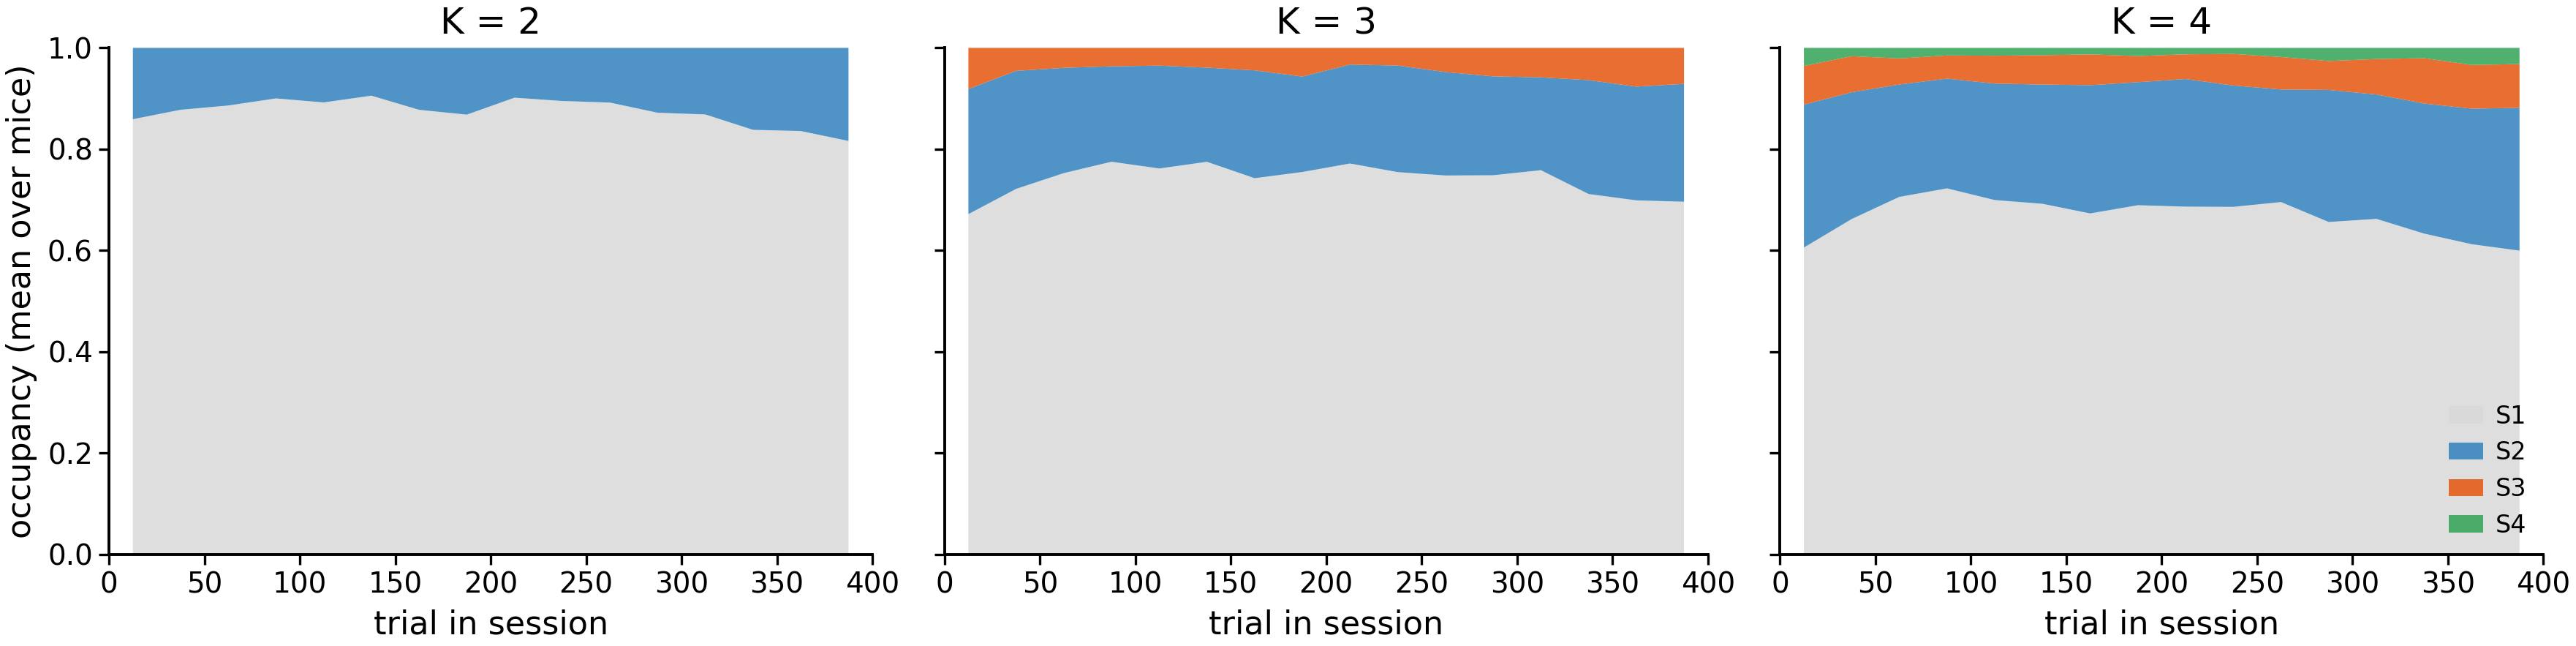

In [9]:
fig, axes = plt.subplots(1, len(KS), figsize=(9, 2.4), sharey=True)
Tq = T[T['trial_idx'] < N_TRUNC].assign(tbin=lambda d: d['trial_idx'] // TIME_BIN * TIME_BIN + TIME_BIN / 2)
for ax, k in zip(axes, KS):
    occ = (Tq.groupby(['mouse_name', 'tbin'])[f'S_K{k}'].value_counts(normalize=True).unstack(fill_value=0)
             .groupby('tbin').mean())
    ax.stackplot(occ.index, occ.T.to_numpy(), colors=[AREA_COLOR[s] for s in occ.columns], alpha=0.85,
                 labels=[f'S{s}' for s in occ.columns])
    ax.set_xlim(0, N_TRUNC); ax.set_ylim(0, 1); ax.set_xlabel('trial in session'); ax.set_title(f'K = {k}')
axes[0].set_ylabel('occupancy (mean over mice)'); axes[-1].legend(frameon=False, fontsize=6, loc='lower right')
fig.tight_layout(); plt.show()

### Example sessions

The same two sessions at K = 2, 3, 4: the posterior of every state per trial, stacked (engaged S1 pale at the bottom, the other states in colour above it), over the first `N_TRUNC` trials. One session from each end of LD1 (closest to the 10th and 90th percentile of session LD1).

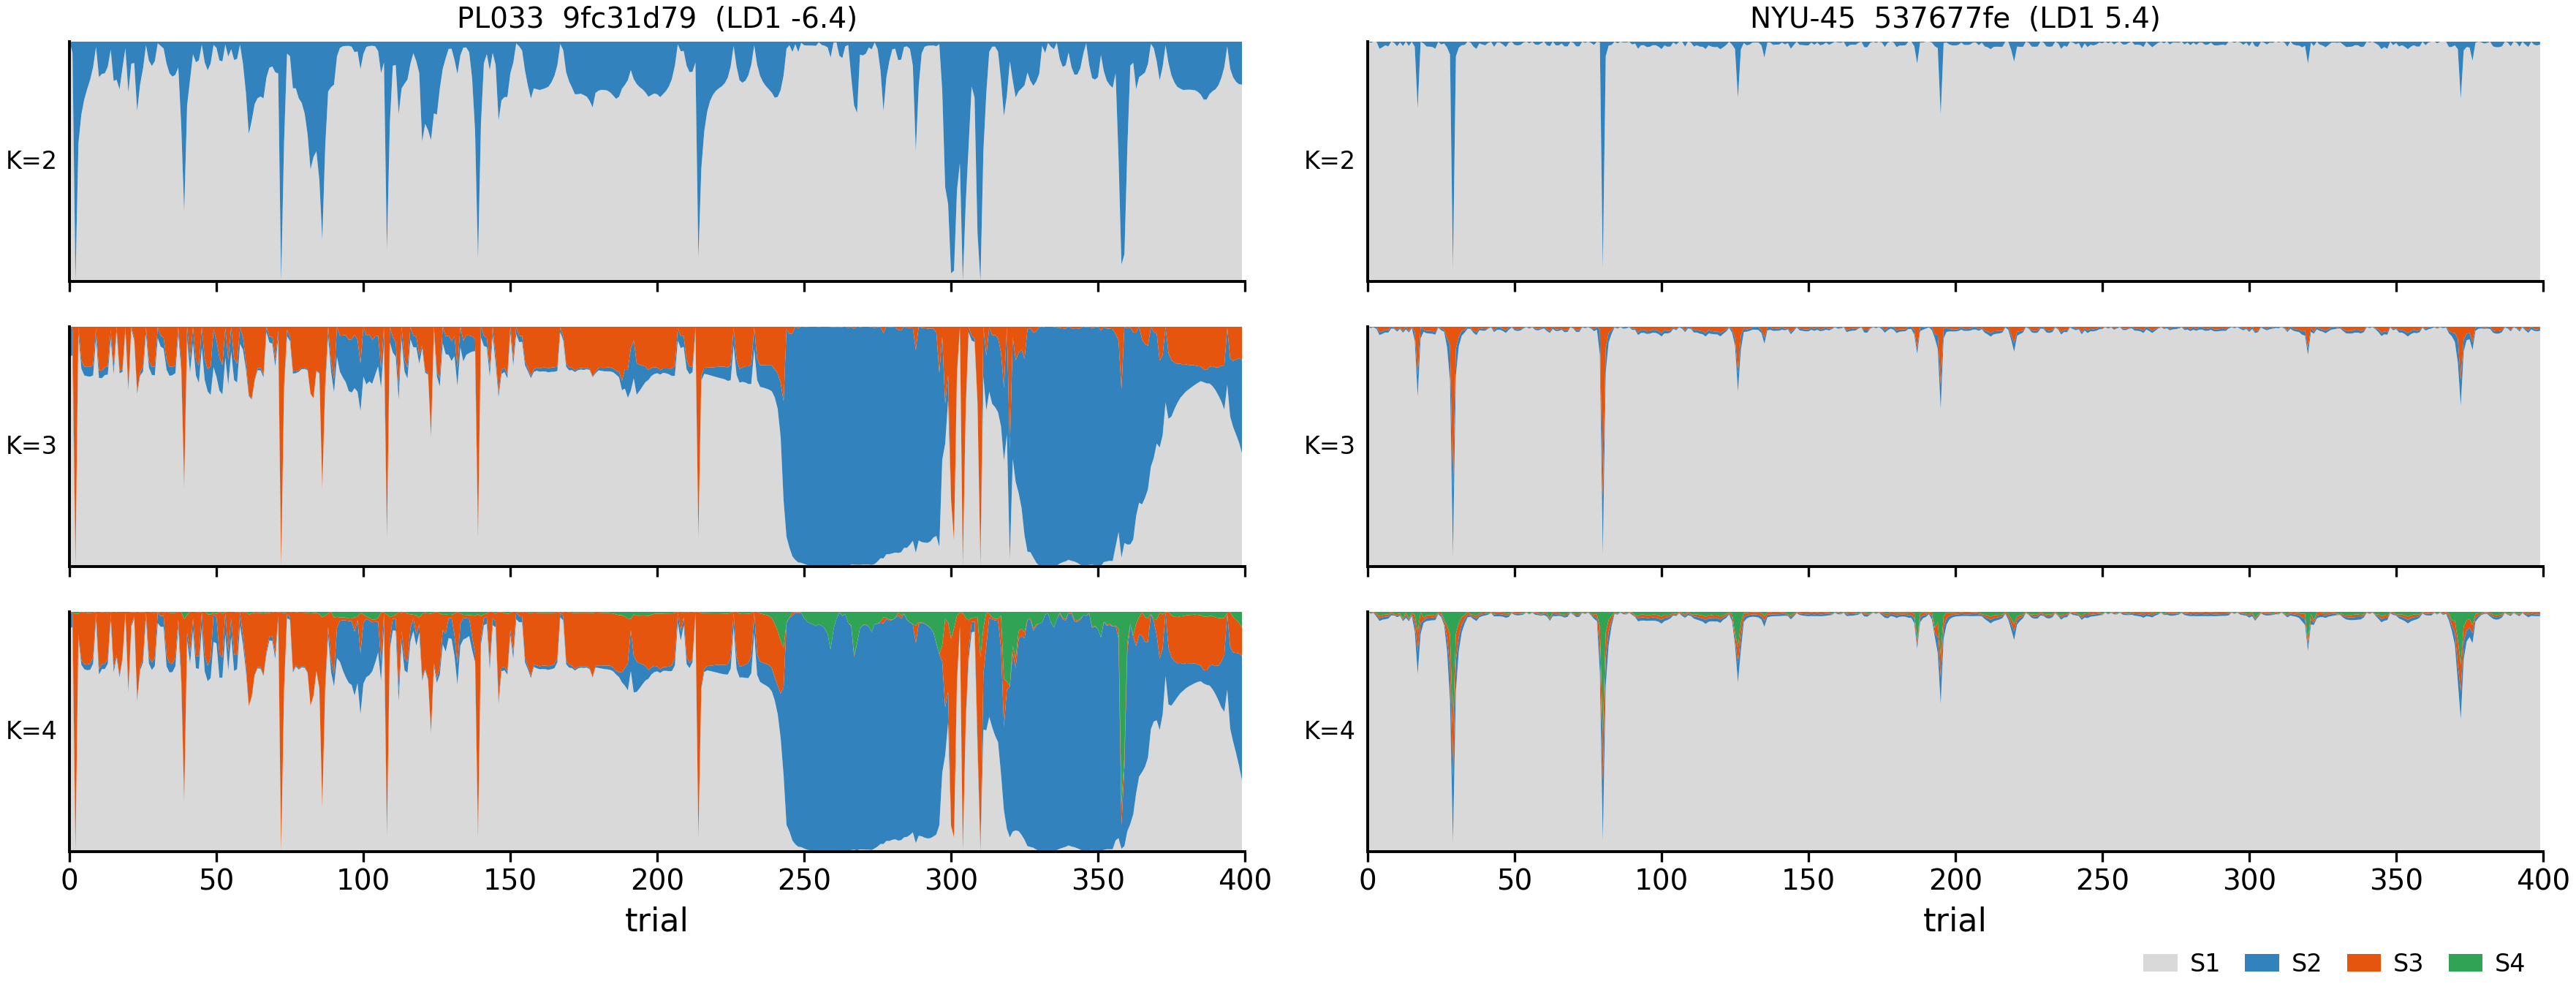

In [10]:
sess_ld1 = lda.set_index('session')['LD1'].reindex(T['eid'].unique()).dropna()
MOUSE_OF = T.drop_duplicates('eid').set_index('eid')['mouse_name']

def draw_example(axes_col, e, legend=False):
    # stacked posterior of every state per trial, K = 2, 3, 4 (one axis each), first N_TRUNC trials
    m = MOUSE_OF[e]
    for ax, k in zip(axes_col, KS):
        pk = P.xs((m, e), level=('mouse_name', 'eid'))[k].dropna(axis=1, how='all')
        pk = pk.rename(columns=lambda s: RANK[(m, k, s)]).sort_index(axis=1)
        pk = pk[pk.index < N_TRUNC]
        ax.stackplot(pk.index, pk.T.to_numpy(), colors=[AREA_COLOR[s] for s in pk.columns], lw=0,
                     labels=[f'S{s}' for s in pk.columns])
        ax.set_ylim(0, 1); ax.set_xlim(0, N_TRUNC); ax.set_yticks([])
        ax.text(-0.01, 0.5, f'K={k}', transform=ax.transAxes, ha='right', va='center', fontsize=6)
    axes_col[0].set_title(f"{m}  {e[:8]}  (LD1 {sess_ld1[e]:.1f})", fontsize=7)
    if legend:
        axes_col[-1].legend(frameon=False, fontsize=6, ncol=4, loc='upper right', bbox_to_anchor=(1, -0.35))

EX = [sess_ld1.sub(sess_ld1.quantile(q)).abs().idxmin() for q in (0.1, 0.9)]
fig, axes = plt.subplots(len(KS), 2, figsize=(9, 1.0 * len(KS) + 0.6), sharex=True)
for c, e in enumerate(EX):
    draw_example(axes[:, c], e, legend=c == 1)
    axes[-1, c].set_xlabel('trial')
fig.tight_layout(); plt.show()

### More example sessions, across LD1

`N_EXAMPLE_PAIRS` pairs, each a low- and a high-LD1 session taken symmetrically from the two tails (quantiles `EX_QUANTILES` and 1 − q), each from a different mouse (the session closest to the quantile among mice not shown yet). Same drawing as above: the posterior of every state, stacked, engaged (S1) pale at the bottom.

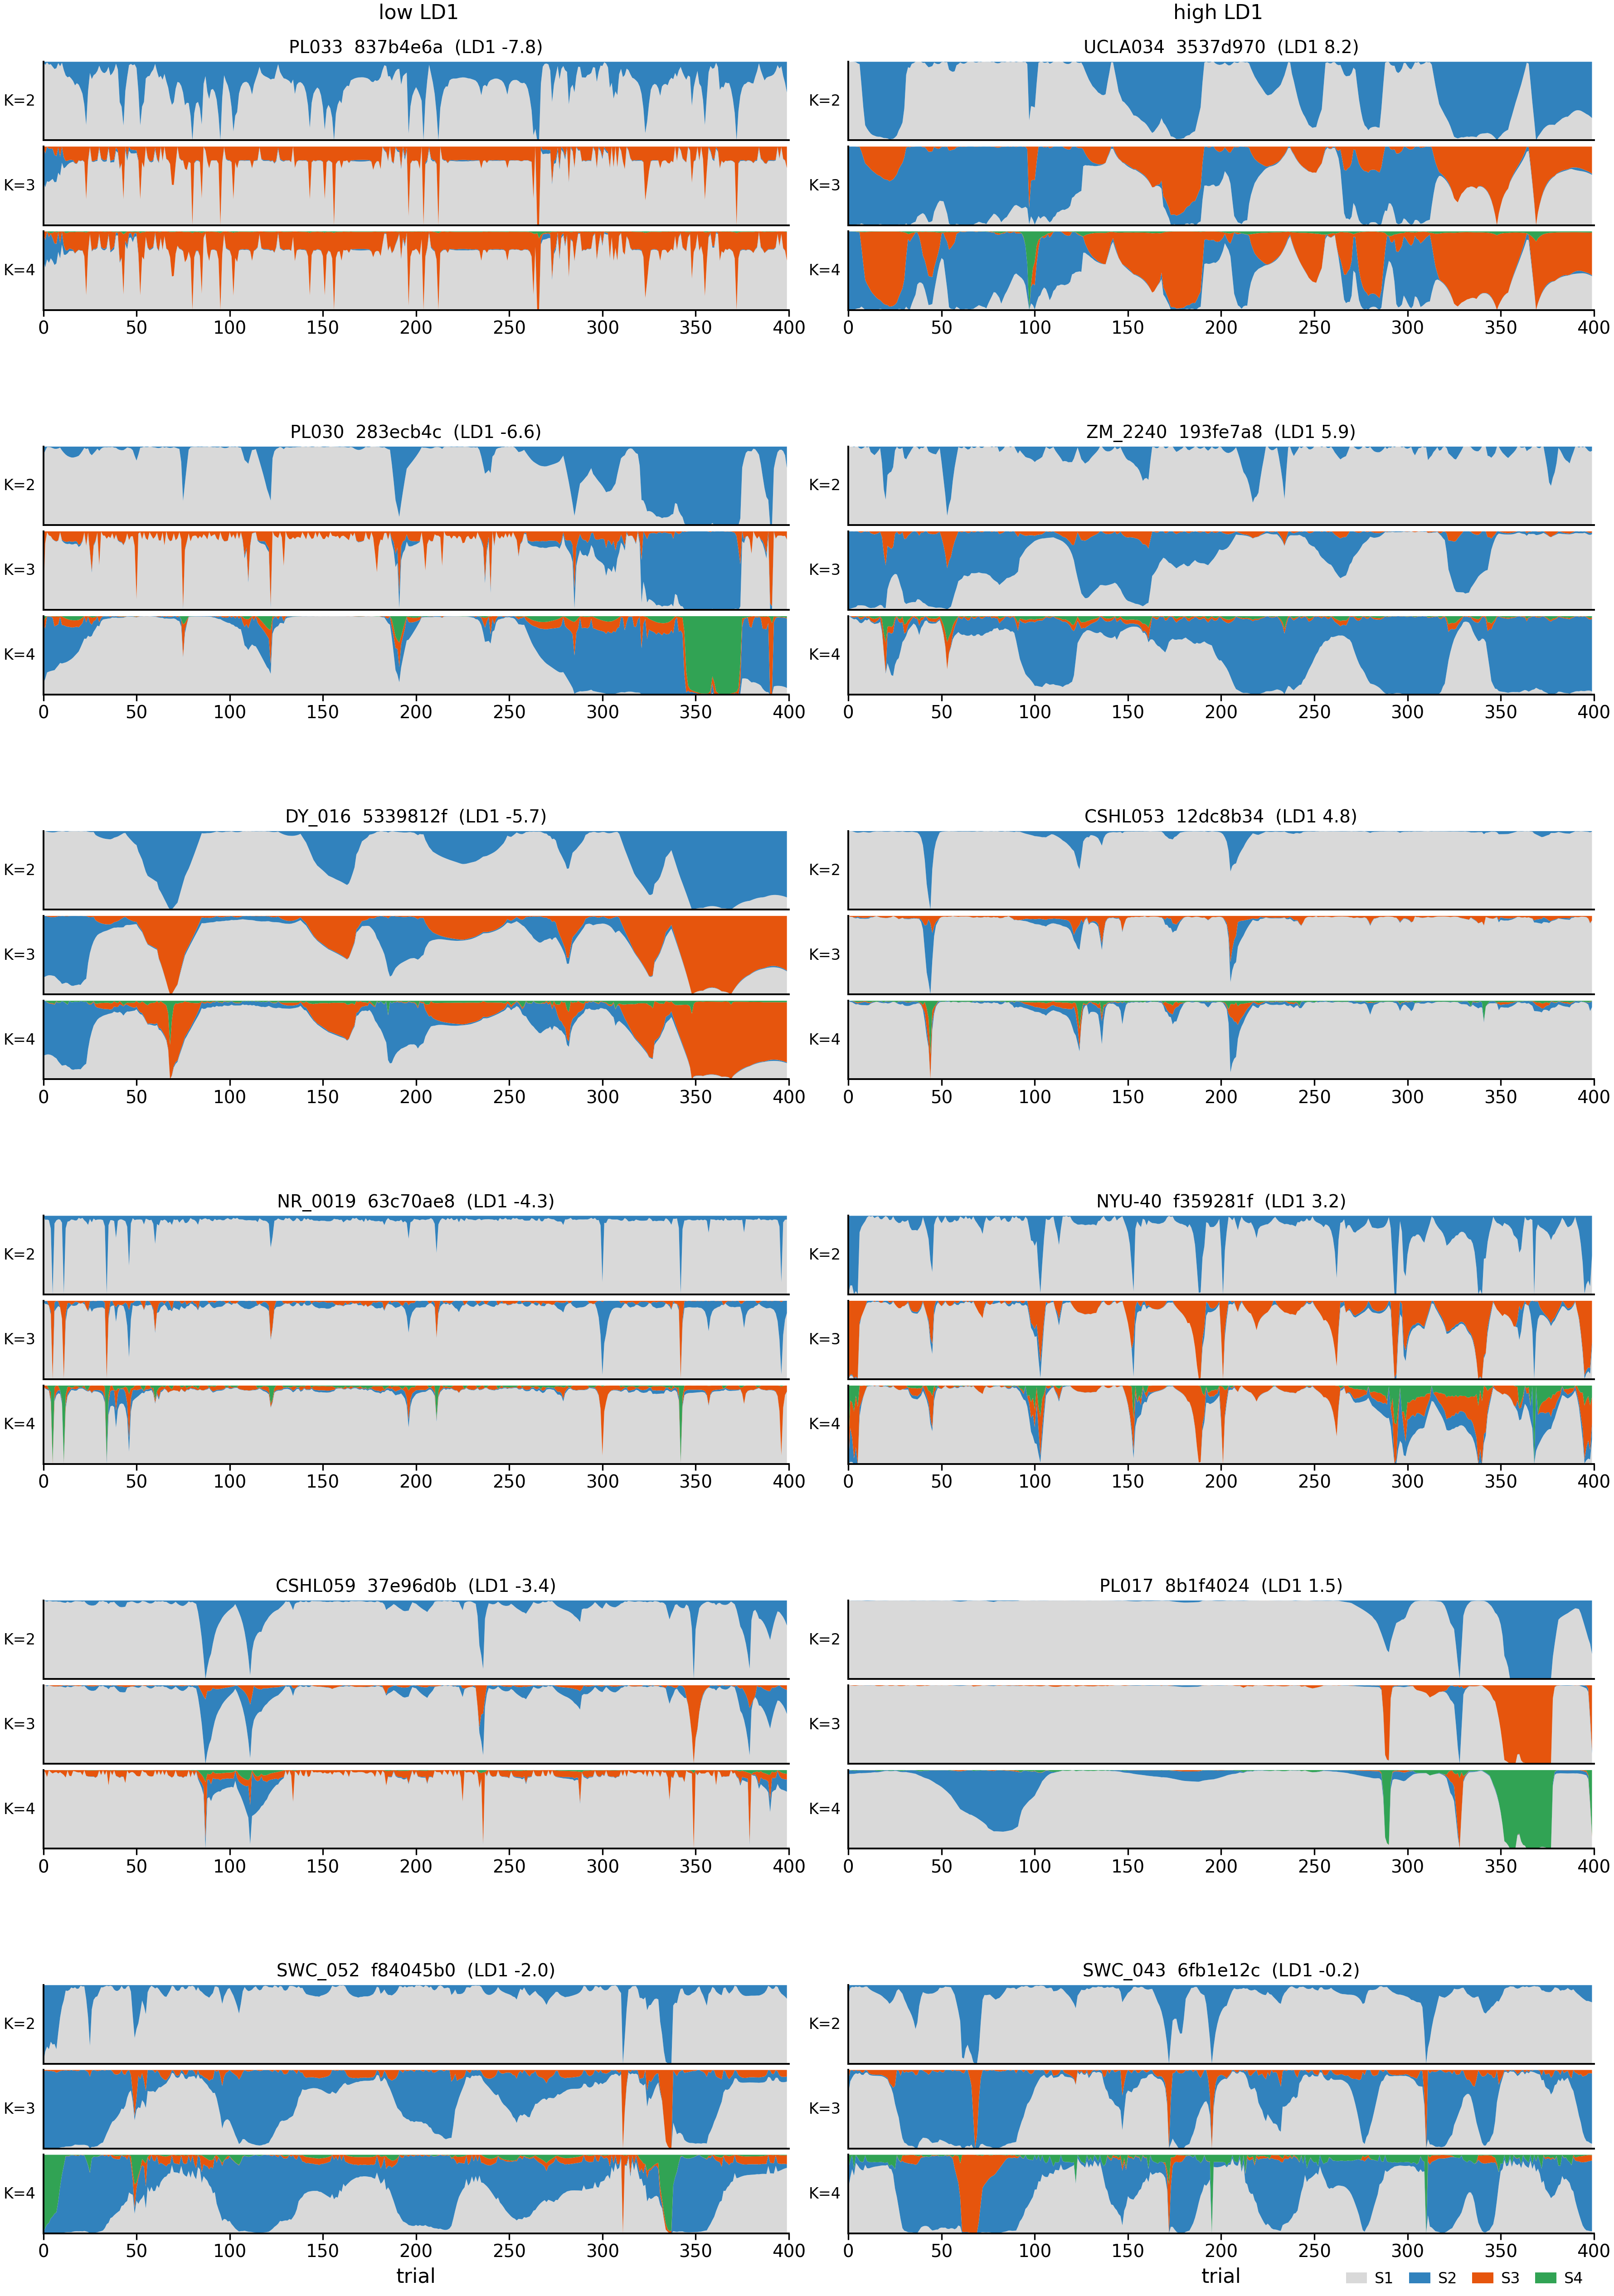

In [11]:
EX_QUANTILES = [0.03, 0.08, 0.15, 0.22, 0.3, 0.4]     # low side; the high side is 1 - q
used, pairs = set(), []
for q in EX_QUANTILES:
    pair = []
    for qq in (q, 1 - q):
        cand = sess_ld1[~MOUSE_OF.reindex(sess_ld1.index).isin(used)]
        e = cand.sub(sess_ld1.quantile(qq)).abs().idxmin()
        used.add(MOUSE_OF[e]); pair.append(e)
    pairs.append(pair)

fig = plt.figure(figsize=(9, 1.25 * len(KS) * len(pairs) * 0.55 + 0.5))
outer = fig.add_gridspec(len(pairs), 2, hspace=0.55, wspace=0.08, left=0.04, right=0.99, top=0.97, bottom=0.04)
for r, pair in enumerate(pairs):
    for c, e in enumerate(pair):
        sub = outer[r, c].subgridspec(len(KS), 1, hspace=0.08)
        axs = [fig.add_subplot(sub[i]) for i in range(len(KS))]
        for a in axs[:-1]:
            a.set_xticks([])
        draw_example(axs, e, legend=(r == len(pairs) - 1 and c == 1))
        if r == len(pairs) - 1:
            axs[-1].set_xlabel('trial')
fig.text(0.27, 0.995, 'low LD1', ha='center', va='top', fontsize=8)
fig.text(0.76, 0.995, 'high LD1', ha='center', va='top', fontsize=8)
plt.show()

## 5. Along LD1 (mouse level)

Per mouse (sessions pooled): occupancy, number of bouts per 100 trials, and mean bout length of each state, against mouse-mean LD1. Pearson; uncorrected p printed (exploratory).

                           p                                               r                           
measure bouts per 100 trials mean bout length occupancy bouts per 100 trials mean bout length occupancy
K state                                                                                                
2 S1                   0.026            0.029     0.686               -0.309            0.303     0.057
  S2                   0.033            0.392     0.686               -0.297            0.121    -0.057
3 S1                   0.014            0.127     0.952               -0.340            0.214     0.009
  S2                   0.521            0.638     0.941               -0.091           -0.067    -0.010
  S3                   0.013            0.233     0.992               -0.344            0.168     0.001
4 S1                   0.052            0.208     0.845               -0.271            0.178     0.028
  S2                   0.737            0.375     0.485         

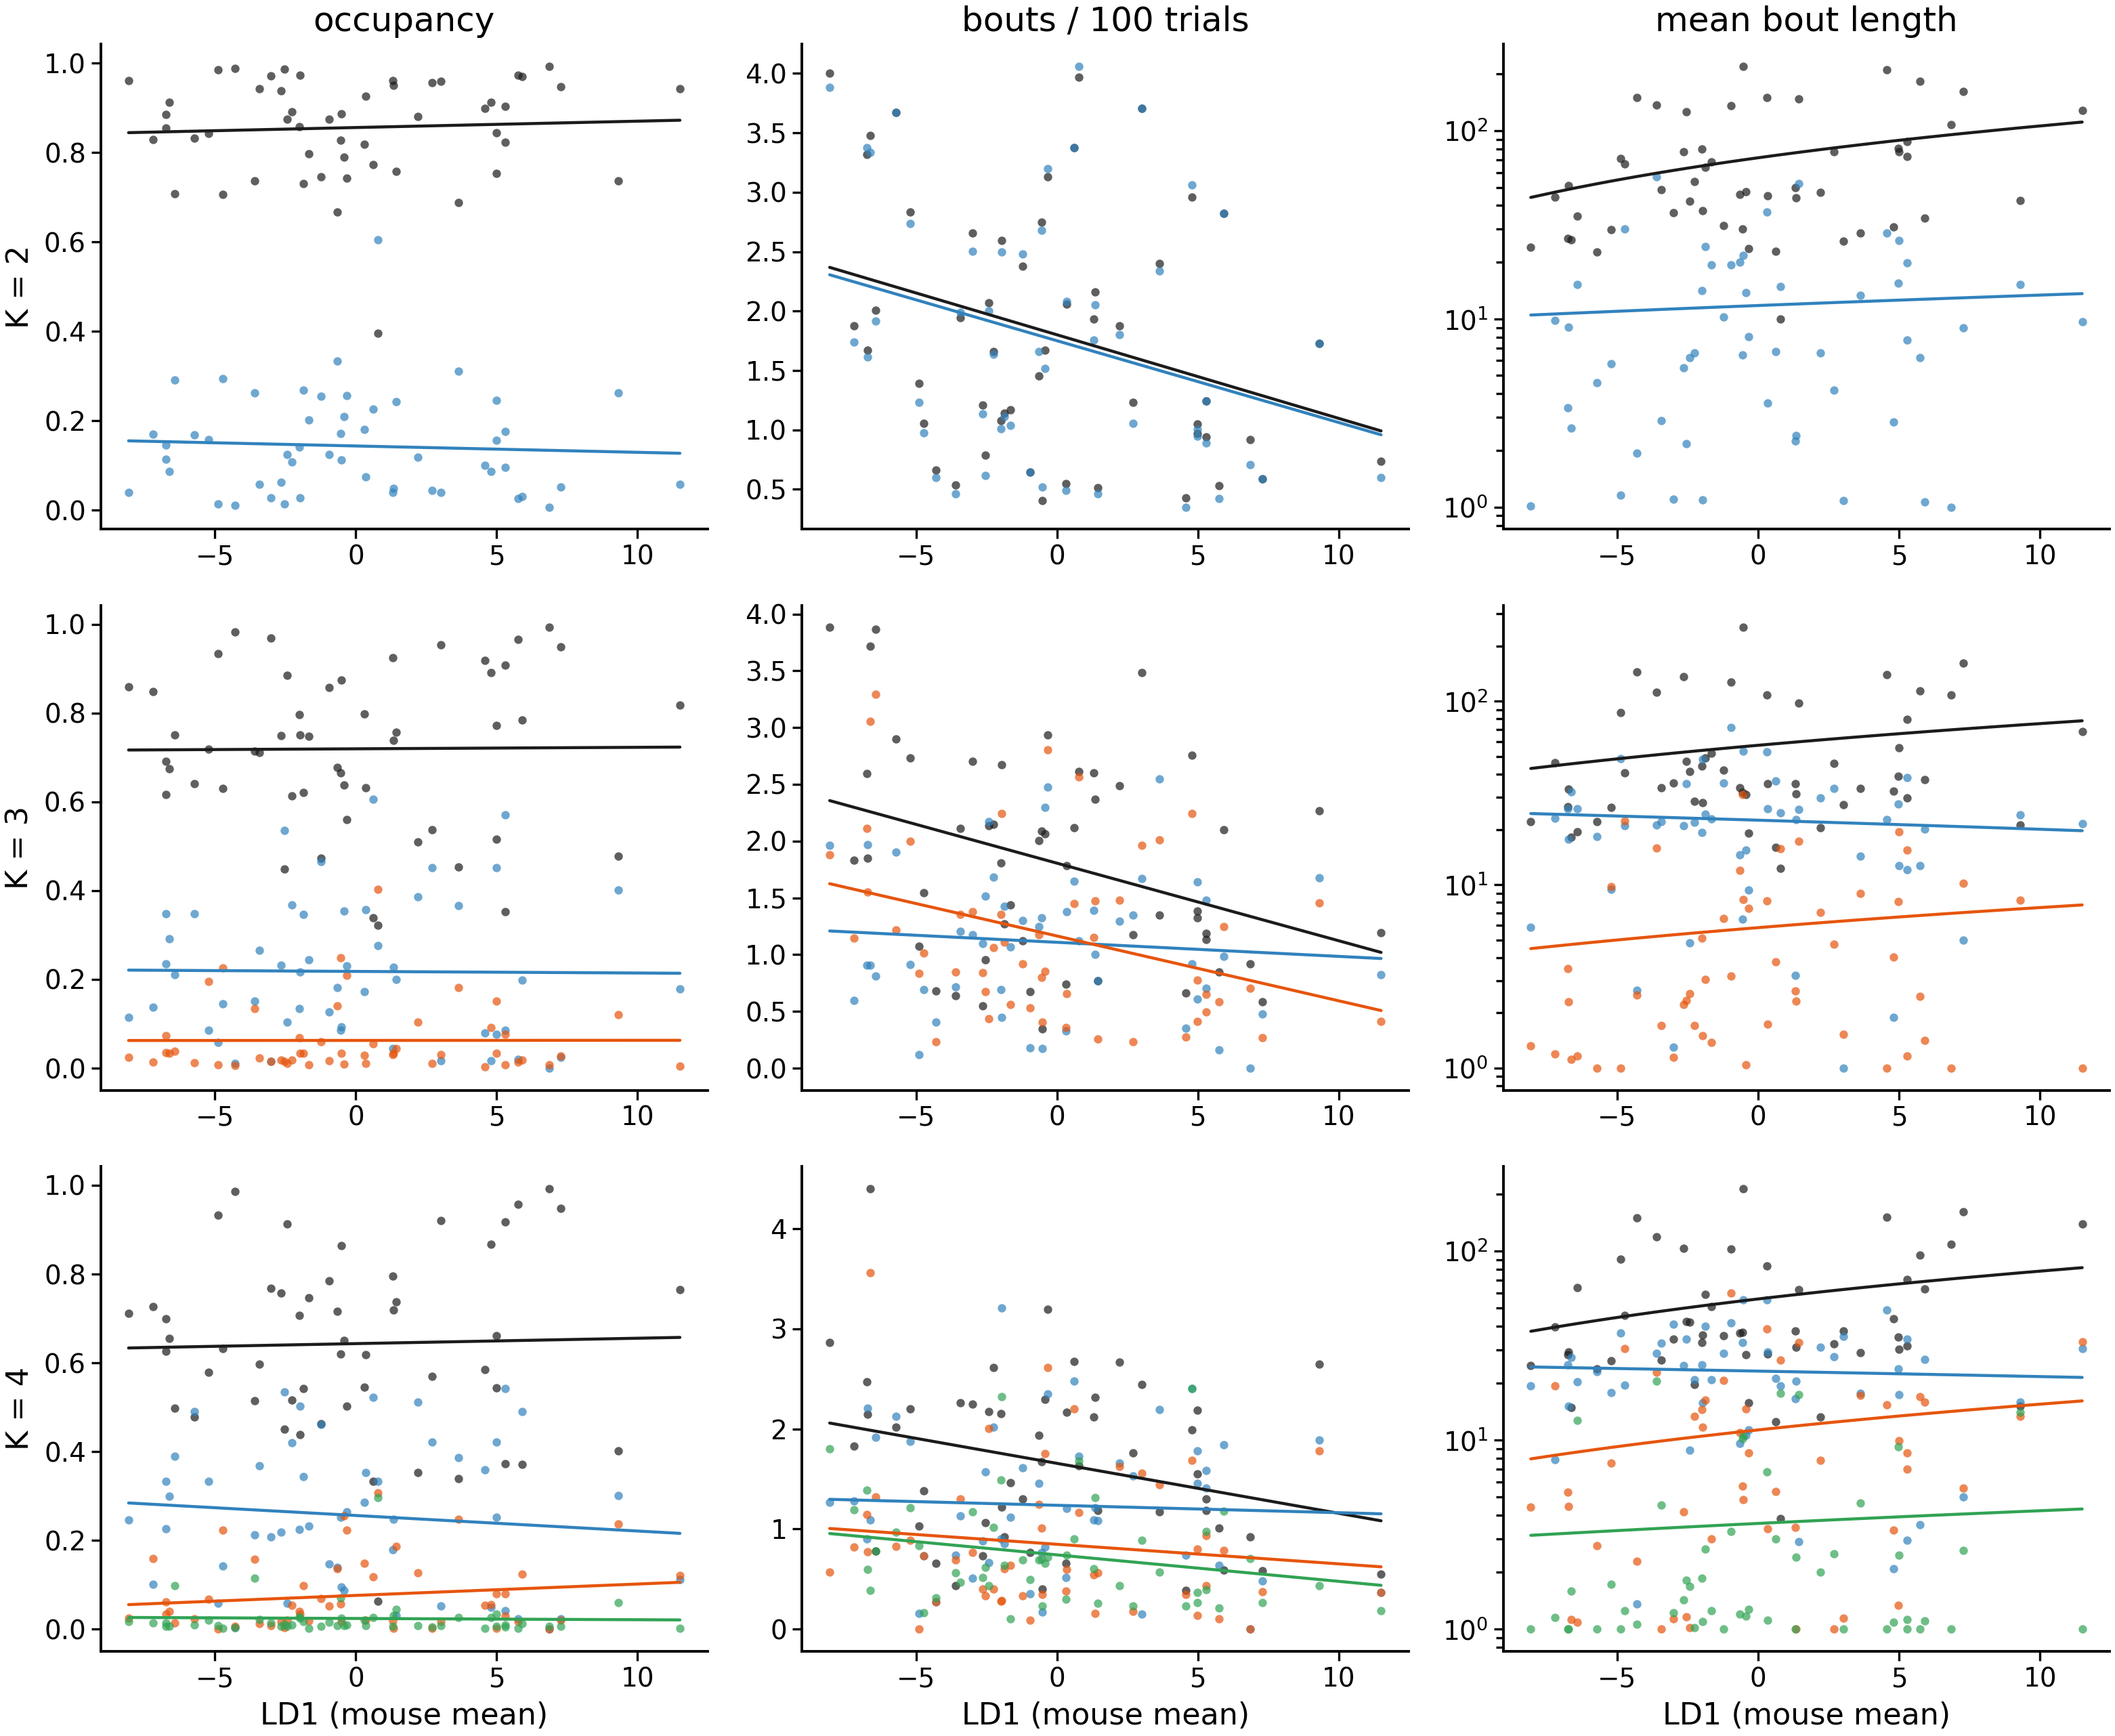

In [12]:
rows = []
for k in KS:
    bk = B[B['K'] == k]
    n_tr = T.groupby('mouse_name').size()
    for s in range(1, k + 1):
        occ = T.assign(x=T[f'S_K{k}'] == s).groupby('mouse_name')['x'].mean()
        nb = bk[bk['state'] == s].groupby('mouse_name').size().reindex(n_tr.index, fill_value=0) / n_tr * 100
        ml = bk[bk['state'] == s].groupby('mouse_name')['length'].mean()
        for name, v in [('occupancy', occ), ('bouts per 100 trials', nb), ('mean bout length', np.log10(ml))]:
            d = pd.concat([v.rename('y'), LD1_MOUSE.rename('LD1')], axis=1).dropna()
            r, p = pearsonr(d['LD1'], d['y'])
            rows.append(dict(K=k, state=f'S{s}', measure=name, r=r, p=p, n=len(d)))
LD1_TAB = pd.DataFrame(rows)
print(LD1_TAB.pivot_table(index=['K', 'state'], columns='measure', values=['r', 'p']).round(3).to_string())

fig, axes = plt.subplots(len(KS), 3, figsize=(8, 2.2 * len(KS)))
for r, k in enumerate(KS):
    bk = B[B['K'] == k]; n_tr = T.groupby('mouse_name').size()
    for s in range(1, k + 1):
        occ = T.assign(x=T[f'S_K{k}'] == s).groupby('mouse_name')['x'].mean()
        nb = bk[bk['state'] == s].groupby('mouse_name').size().reindex(n_tr.index, fill_value=0) / n_tr * 100
        ml = bk[bk['state'] == s].groupby('mouse_name')['length'].mean()
        for c, v in enumerate([occ, nb, ml]):
            d = pd.concat([v.rename('y'), LD1_MOUSE.rename('LD1')], axis=1).dropna()
            axes[r, c].scatter(d['LD1'], d['y'], s=5, color=RANK_COLOR[s], alpha=0.7, lw=0)
            b1, b0 = np.polyfit(d['LD1'], d['y'], 1)
            axes[r, c].plot(np.sort(d['LD1']), b0 + b1 * np.sort(d['LD1']), color=RANK_COLOR[s], lw=0.8)
    axes[r, 0].set_ylabel(f'K = {k}')
    axes[r, 2].set_yscale('log')
for c, t in enumerate(['occupancy', 'bouts / 100 trials', 'mean bout length']):
    axes[0, c].set_title(t); axes[-1, c].set_xlabel('LD1 (mouse mean)')
fig.tight_layout(); plt.show()

## Summary

* **K = 2's disengaged state is a mixture of two time scales.** K = 3 splits it (44% / 34% of its trials) into **S2**, a *slow, less sensitive and biased* state (stimulus weight ~2.7 vs 8.2, |bias| 1.2; easy-trial accuracy 0.87; bouts of ~15–18 trials; 20% of trials), which also takes 18% of the trials K = 2 called engaged, and **S3**, *brief lapses* (bouts of ~2 trials, 3% of trials, easy-trial accuracy 0.26, high previous-choice weight).
* **K = 4 refines both**: S2 becomes a nearly-engaged state (stimulus 5.5, accuracy 0.96, bouts ~20 trials); the old S2/S3 trials split into a biased state (stimulus 1.7, |bias| 1.4, perseverative, bouts ~5) and single-trial lapses (S4, bouts of 1, 1% of trials). The non-engaged states lean to opposite sides in 72% of mice at K = 4 (50% at K = 3): the classic biased-left / biased-right split appears only once the lapses have their own state.
* **RT, which the model never sees, orders the states the same way**: engaged fastest; the slow and biased states slower at low contrast; the K = 4 lapse state slowest (~0.4 s at 0% contrast). So the extra states are not just a reshuffling of errors.
* **Within the session**: the slow less-sensitive state is commonest in the first ~25 trials (warm-up) and grows again late, together with the biased and lapse states (fatigue / satiety); engagement peaks ~100 trials in.
* **Along LD1 (mouse level, uncorrected)**: occupancy of no state tracks LD1 at any K. What tracks it is the number of bouts of the engaged state and of the **brief-lapse** state (K = 3: r = −0.34 for both, p ≈ 0.01), not of the slow state (r = −0.09). Low-LD1 mice lapse briefly more often; they do not spend more time in long sloppy epochs — the same conclusion as `fig_engagement` panel i, now with the two kinds of disengagement separated by the model itself.

**Caveat.** Per-state psychometric curves and accuracies use hard labels from the smoothed posterior, which conditions on each trial's own choice, so they are partly circular (a lapse state's trials are selected for errors). The weights and the RTs are the non-circular descriptions. States are matched across mice by stimulus-weight rank, which is clean for S1 and approximate beyond it. The K = 2 here is the refit in `all_k_*` (r = 0.89 with `fig_engagement`'s posteriors).